In [2]:
import torch
from torch import nn, optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, ConcatDataset
from torchvision.datasets import ImageFolder
import os

In [3]:

# Define the path to the dataset
dataset_path = 'C:\\Users\\KIIICK\\Documents\\Projects\\Python\\Computer Vision Project\\Datasets\\InsPLAD\\InsPLAD-fault\\defect_supervised'

# Transforms for the input data
transformations = transforms.Compose([
    transforms.Resize((224, 224)),  # Resize images to 224x224 for DenseNet
    transforms.ToTensor(),  # Convert images to tensor
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])  # Normalize images
])


In [4]:

# Helper function to load data from multiple subdirectories
def load_data_from_folders(base_dir, transform):
    data_folders = []
    for defect_type in ['yoke-suspension', 'glass-insulator', 'polymer-insulator-upper-shackle', 'lightning-rod-suspension', 'vari-grip']:
        train_path = os.path.join(base_dir, defect_type, 'train')
        if os.path.exists(train_path):
            data_folders.append(ImageFolder(train_path, transform=transform))
        val_path = os.path.join(base_dir, defect_type, 'val')
        if os.path.exists(val_path):
            data_folders.append(ImageFolder(val_path, transform=transform))
    return ConcatDataset(data_folders)


In [5]:

# Load datasets
train_data = load_data_from_folders(dataset_path, transformations)
val_data = load_data_from_folders(dataset_path, transformations)


In [6]:

# Data loaders
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
val_loader = DataLoader(val_data, batch_size=32, shuffle=False)


In [11]:

# Initialize the model
model = models.densenet121(pretrained=True)
num_ftrs = model.classifier.in_features
model.classifier = nn.Linear(num_ftrs, 3)  # Assuming binary classification (good, rust)


In [12]:

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)


In [17]:
'''def train_model(model, criterion, optimizer, num_epochs=10):
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    model.to(device)
    print(device)

    for epoch in range(num_epochs):
        print("Starting training...")
        print("Number of training batches:", len(train_loader))

        model.train()
        running_loss = 0.0
        batch_count = 0  # To count the number of batches processed

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * inputs.size(0)
            batch_count += 1
        
        epoch_loss = running_loss / len(train_loader.dataset)
        print(f'Epoch {epoch+1}/{num_epochs}, Batch processed: {batch_count}, Loss: {epoch_loss:.4f}')
        
        # Validation phase
        model.eval()
        val_running_loss = 0.0
        val_batch_count = 0  # To count the number of validation batches processed

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_running_loss += loss.item() * inputs.size(0)
                val_batch_count += 1
                
        val_epoch_loss = val_running_loss / len(val_loader.dataset)
        print(f'Validation - Epoch {epoch+1}/{num_epochs}, Batch processed: {val_batch_count}, Loss: {val_epoch_loss:.4f}')
        
    return model
'''

In [21]:
from tqdm import tqdm

def train_model(model, criterion, optimizer, num_epochs=10):
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    model.to(device)

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        train_loader_progress = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} (Training)", unit="batch")

        for inputs, labels in train_loader_progress:
            inputs, labels = inputs.to(device), labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * inputs.size(0)
            train_loader_progress.set_postfix(loss=(running_loss / ((train_loader_progress.n + 1) * train_loader.batch_size)))

        epoch_loss = running_loss / len(train_loader.dataset)
        
        # Validation phase
        model.eval()
        val_running_loss = 0.0
        val_loader_progress = tqdm(val_loader, desc=f"Epoch {epoch+1}/{num_epochs} (Validation)", unit="batch")

        with torch.no_grad():
            for inputs, labels in val_loader_progress:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_running_loss += loss.item() * inputs.size(0)
                val_loader_progress.set_postfix(loss=(val_running_loss / ((val_loader_progress.n + 1) * val_loader.batch_size)))
        
        val_epoch_loss = val_running_loss / len(val_loader.dataset)
        print(f'Validation completed - Loss: {val_epoch_loss:.4f}')

    return model


In [22]:

# Train the model
trained_model = train_model(model, criterion, optimizer, num_epochs=10)


Epoch 1/10 (Training):   0%|          | 0/312 [00:00<?, ?batch/s]

Epoch 1/10 (Validation): 100%|██████████| 312/312 [06:09<00:00,  1.19s/batch, loss=0.0984]


Validation completed - Loss: 0.0984


Epoch 2/10 (Validation): 100%|██████████| 312/312 [06:10<00:00,  1.19s/batch, loss=0.07]  


Validation completed - Loss: 0.0700


...

Validation completed - Loss: 0.0326


Epoch 9/10 (Validation): 100%|██████████| 312/312 [06:09<00:00,  1.18s/batch, loss=0.0416] 


Validation completed - Loss: 0.0416


Epoch 10/10 (Validation): 100%|██████████| 312/312 [06:09<00:00,  1.18s/batch, loss=0.0557]

Validation completed - Loss: 0.0558


In [23]:
# Save the trained model
model_path = 'trained_densenet121.pth'
torch.save(model.state_dict(), model_path)
print(f"Model saved to {model_path}")


Model saved to trained_densenet121.pth


In [25]:
# Load the trained model for testing
model = models.densenet121(pretrained=True)  # Reinitialize the model architecture
num_ftrs = model.classifier.in_features
model.classifier = nn.Linear(num_ftrs, 3)  # Adjust the final layer accordingly

model.load_state_dict(torch.load(model_path))
model.eval()  # Set the model to evaluation mode

print("Model loaded and set to evaluation mode.")


Model loaded and set to evaluation mode.


C:\Users\KIIICK\AppData\Local\Temp\ipykernel_23020\2636734830.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(model_path))


In [29]:
from torch.utils.data import random_split

def load_data_with_test_split(base_dir, transform, test_split=0.2):
    data_folders = []
    test_folders = []
    for defect_type in ['yoke-suspension', 'glass-insulator', 'polymer-insulator-upper-shackle', 'lightning-rod-suspension', 'vari-grip']:
        data_path = os.path.join(base_dir, defect_type)
        full_data = ImageFolder(os.path.join(data_path, 'val'), transform=transform)
        test_size = int(len(full_data) * test_split)
        val_size = len(full_data) - test_size
        val_subset, test_subset = random_split(full_data, [val_size, test_size])
        data_folders.append(val_subset)
        test_folders.append(test_subset)
    return ConcatDataset(data_folders), ConcatDataset(test_folders)

# Load validation and test datasets
val_data, test_data = load_data_with_test_split(dataset_path, transformations, test_split=0.2)

# Data loaders for validation and test
val_loader = DataLoader(val_data, batch_size=32, shuffle=False)
test_loader = DataLoader(test_data, batch_size=32, shuffle=False)


In [33]:
import matplotlib.pyplot as plt

# Testing the model and collecting accuracy for each batch
batch_accuracies = []
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model.to(device)

model.eval()  # Ensure the model is in evaluation mode
with torch.no_grad():
    total = 0
    correct = 0
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
        batch_accuracy = 100 * (predicted == labels).sum().item() / labels.size(0)
        batch_accuracies.append(batch_accuracy)

overall_accuracy = 100 * correct / total
print(f'Overall accuracy of the model on the test images: {overall_accuracy:.2f}%')



Overall accuracy of the model on the test images: 98.13%


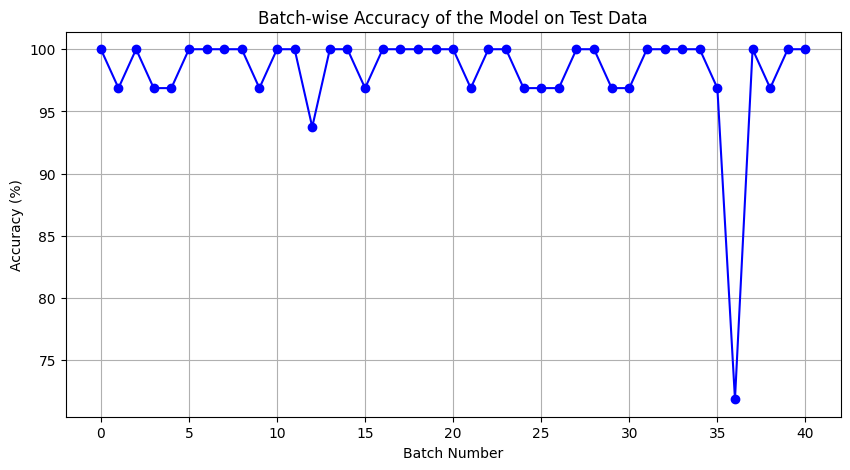

In [34]:
# Plotting the accuracies
plt.figure(figsize=(10, 5))
plt.plot(batch_accuracies, marker='o', linestyle='-', color='b')
plt.title('Batch-wise Accuracy of the Model on Test Data')
plt.xlabel('Batch Number')
plt.ylabel('Accuracy (%)')
plt.grid(True)
plt.show()


 * Serving Flask app '__main__'
 * Debug mode: on


C:\Users\KIIICK\AppData\Local\Temp\ipykernel_23020\1774309556.py:13: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('trained_densenet121.pth'

SystemExit: 1